# Comparison of the 2D Projections of the Iris Dataset by PCA and LDA

The Iris dataset describes 3 species of iris (setosa, versicolor and virginica) by 4 attributes: sepal length, sepal width, petal length and petal width.

Principal component analysis (PCA) applied to this data identifies the combinations of attributes (principal components, or directions in the feature space) that explain the most variance in the data. Here we plot the samples on the first 2 principal components.

Linear discriminant analysis (LDA) looks for the axes that maximize the ratio of between-class variance to within-class variance. Unlike PCA, LDA is a supervised method, which uses the known classes; it gives at most C − 1 axes for C classes.

This notebook is largely based on a [scikit-learn code example](https://scikit-learn.org/stable/auto_examples/decomposition/plot_pca_vs_lda.html).

## The data

The 4 attributes are standardized, so that each one has the same weight in the PCA.

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler

iris = load_iris()
print(iris.feature_names)
X = StandardScaler().fit_transform(iris.data)
y = iris.target
target_names = iris.target_names
colors = ["navy", "turquoise", "darkorange"]


def plot_projection(Z, title):
  # Plots a 2D projection, one point per flower, one color per species
  plt.figure()
  for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(Z[y == i, 0], Z[y == i, 1], color=color, alpha=0.8, label=target_name)
  plt.legend(loc="best", shadow=False, scatterpoints=1)
  plt.title(title)
  plt.show()

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


## PCA

Explained variance ratio of each component: [0.73 0.23]


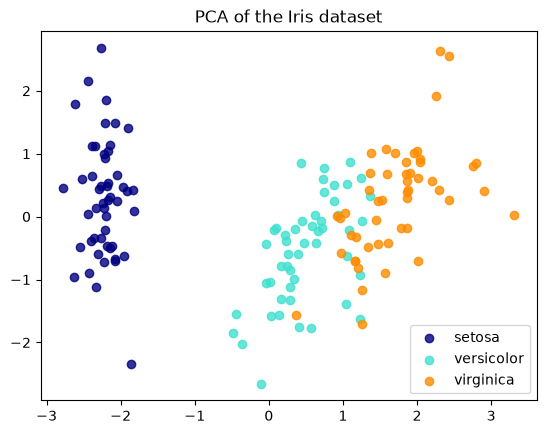

In [2]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print(
  f"Explained variance ratio of each component: {pca.explained_variance_ratio_.round(2)}"
)
plot_projection(X_pca, "PCA of the Iris dataset")

The first two components keep 73% and 23% of the variance, 96% together. Setosa stands apart; versicolor and virginica overlap a little: PCA doesn't know the species.

## LDA

Share of the separation carried by each axis: [0.99 0.01]


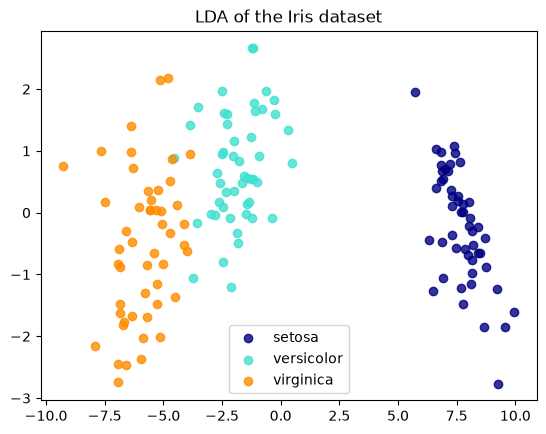

In [3]:
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)
print(
  f"Share of the separation carried by each axis: {lda.explained_variance_ratio_.round(2)}"
)
plot_projection(X_lda, "LDA of the Iris dataset")

LDA gives 2 axes, C − 1 for 3 species. Its `explained_variance_ratio_` is the share of the separation between classes each axis carries (99% and 1%), not a share of the data's variance. On the first axis, versicolor and virginica overlap less than on the PCA.

## Comparison

- PCA, unsupervised, keeps the largest variance of the measurements; LDA, supervised, separates the classes it's given.
- LDA separates versicolor and virginica better, because it uses the species.
- On Iris, the two maps look alike, because the size of the petals, the axis of largest variance, is also what tells the species apart: that isn't always the case.